# Project 2 – Logistic regression: latent space with t-SNE and UMAP
Based on the Week 9 exercise (*LatentVisualization*), but with our own logistic regression model instead of the MNIST CNN.

**Important difference from the NN:** logistic regression has no hidden layers. The model is just

$$\text{logit}(x) = b + \sum_j w_j x_j$$

so there are only two representations to look at:

| Representation | What it is |
|---|---|
| **Input x** (21-D) | the standardized features, before the model does anything |
| **Weighted inputs w·x** (21-D) | each feature multiplied by its weight = the feature's contribution to the logit (equal to the exact SHAP values for a linear model, up to a constant per feature) |

The logit itself is 1-D, so it does not need t-SNE (Section 3.2 shows it directly).

| Week 9 (MNIST CNN) | This notebook (logistic regression) |
|---|---|
| c1–c4 feature maps | input x, weighted inputs w·x |
| Exercise 1: t-SNE vs PCA | Section 4 |
| Exercise 3: perplexity | Section 5 |
| Exercise 4: UMAP | Section 6 |

Exercise 2 (rotational augmentation) is image-specific and is left out.

We do **not** train a new model: the trained model and data split are loaded by running `Project2_LogReg_clean.ipynb` (Section 2).

## 1. Setup

In [1]:
%pip install umap-learn scikit-learn pandas numpy matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.


## 2. Load our trained model from `Project2_LogReg_clean.ipynb`
Instead of training a new model, we run the main notebook in this kernel with `%run`.
That gives us **the same trained `model`**, the same data split (`X_test`, `X_test_raw`, `y_test`, `y012_test`, ...) and the same `FEATURE_COLS`.

The whole main notebook is executed (training, LIME, SHAP, ...), so this cell takes a few minutes.
Its output is hidden with `%%capture`. Run `main_log.show()` in a new cell to see it.

In [2]:
%%capture main_log
%run Project2_LogReg_clean.ipynb

In [3]:
plt.close('all')   # figures from the main notebook are not needed here

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

warnings.filterwarnings('ignore', message='n_jobs value')   # UMAP warns when random_state is set
warnings.filterwarnings('ignore', message='compatibility_layout', category=FutureWarning)   # UMAP 0.6 notice

SEED = 42
MODEL_TAG = MODEL_TAG   # set by the main notebook
print('Loaded model:', model)

Loaded model: LogisticRegression(class_weight={0: 0.5935372781843838, 1: 3.172731181114672},
                   max_iter=1, random_state=42, warm_start=True)


In [4]:
# Predicted probabilities of the loaded model on the test set
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

print(f'Test balanced accuracy: {balanced_accuracy_score(y_test, test_pred):.3f}   (should match the main notebook)')
print(f'Test ROC-AUC:           {roc_auc_score(y_test, test_proba):.3f}')

Test balanced accuracy: 0.743   (should match the main notebook)
Test ROC-AUC:           0.818


## 3. Representations
Same idea as `features = [x1, x2, x4, x5]` in Week 9, but logistic regression only has the input and the weighted inputs.

In [5]:
# t-SNE and UMAP are slow on the full test set (~50,000 persons), so we use a random sample.
# Same seed and size as in the main notebook -> the same 5000 persons.
N_LATENT = 5000
rng_lat = np.random.default_rng(SEED)
lat_idx = rng_lat.choice(len(X_test), size=N_LATENT, replace=False)

lat_y012 = y012_test[lat_idx]     # true 3-class label
lat_y = y_test[lat_idx].astype(int)   # binary label
lat_proba = test_proba[lat_idx]   # model's predicted probability
lat_raw = X_test_raw[lat_idx]     # unscaled feature values (for colouring by concept)

print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

Classes in the sample (0, 1, 2): [4232   92  676]


In [6]:
X_lat = X_test[lat_idx]
W_lat = X_lat * model.coef_[0]          # (N, 21) * (21,): each feature's contribution to the logit
logit_lat = model.decision_function(X_lat)

# check: summing the contributions + intercept gives back the model's logit
assert np.allclose(W_lat.sum(axis=1) + model.intercept_[0], logit_lat)

reps = {
    'Input x (21, standardized)': X_lat,
    'Weighted inputs w·x (21)': W_lat,
}
MAIN_REP = 'Weighted inputs w·x (21)'   # used for the hyperparameter experiments

for name, R in reps.items():
    print(f'{name:28s} shape {R.shape}')

Input x (21, standardized)   shape (5000, 21)
Weighted inputs w·x (21)     shape (5000, 21)


In [7]:
class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}


def scatter_by_label(ax, emb, labels=None, title='', legend=True, s=4):
    """Scatter a 2-D embedding coloured by the 3-class label.
    The big class (0) is drawn first so the small classes stay visible on top."""
    labels = lat_y012 if labels is None else labels
    for c in [0, 2, 1]:
        mask = labels == c
        ax.scatter(emb[mask, 0], emb[mask, 1], s=s, alpha=0.6, color=class_colors[c],
                   label=f'{class_labels[c]}  n={mask.sum()}')
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    if legend:
        ax.legend(markerscale=3, fontsize=7, loc='best')


def scatter_by_value(ax, emb, values, title='', cmap='viridis', vmin=None, vmax=None, s=4, label=None):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, cmap=cmap, vmin=vmin, vmax=vmax, s=s, alpha=0.7)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

### 3.1 The output (logit) is 1-D
The last "layer" of logistic regression is a single number, so we can look at it directly instead of using t-SNE. Everything the model knows about a person is this one number.

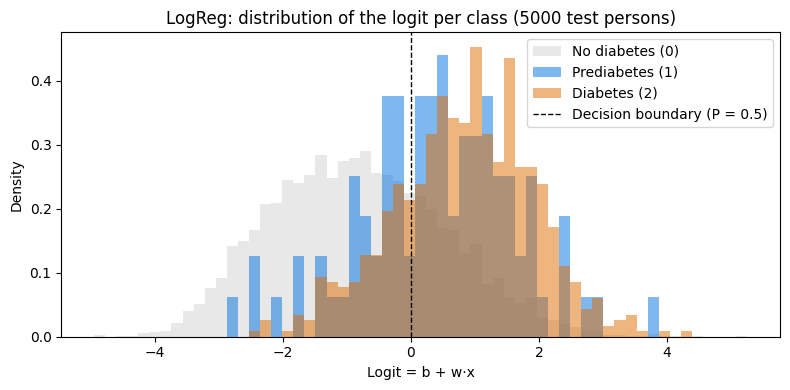

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(logit_lat.min(), logit_lat.max(), 60)
for c in [0, 1, 2]:
    ax.hist(logit_lat[lat_y012 == c], bins=bins, density=True, alpha=0.5,
            color=class_colors[c], label=class_labels[c])
ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Decision boundary (P = 0.5)')
ax.set_xlabel('Logit = b + w·x')
ax.set_ylabel('Density')
ax.set_title(f'{MODEL_TAG}: distribution of the logit per class ({N_LATENT} test persons)')
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Compute PCA, t-SNE and UMAP for both representations

In [9]:
# Default settings (same as in the main notebook)
TSNE_KW = dict(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED)
UMAP_KW = dict(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)

tsne_embs, pca_embs, pca_vars, umap_embs = {}, {}, {}, {}
for name, R in reps.items():
    pca = PCA(n_components=2, random_state=SEED)
    pca_embs[name] = pca.fit_transform(R)
    pca_vars[name] = pca.explained_variance_ratio_
    tsne_embs[name] = TSNE(**TSNE_KW).fit_transform(R)
    umap_embs[name] = umap.UMAP(**UMAP_KW).fit_transform(R)
    print(f'{name:35s} done   (PCA: PC1 {100*pca_vars[name][0]:.1f}%, PC2 {100*pca_vars[name][1]:.1f}%)')

Input x (21, standardized)          done   (PCA: PC1 16.4%, PC2 8.7%)


Weighted inputs w·x (21)            done   (PCA: PC1 37.0%, PC2 22.0%)


### 3.3 t-SNE of each representation
Corresponds to the first plot in Week 9. The weighted inputs stretch the axes that matter for the model (large |w|) and shrink the others, so the class structure should be clearer than in the raw input.

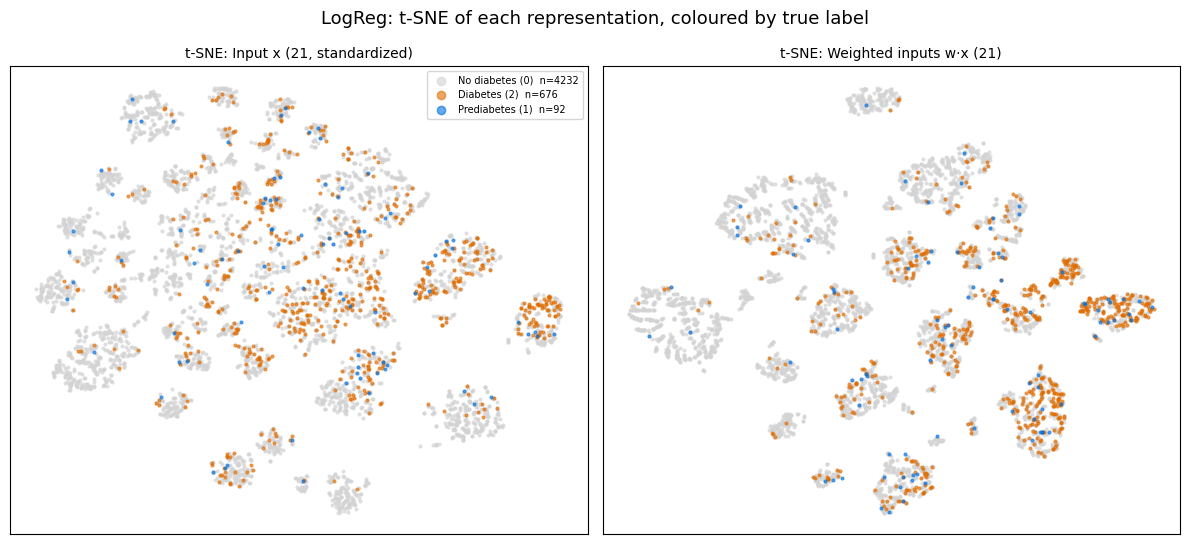

In [10]:
fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5.5))
for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), reps)):
    scatter_by_label(ax, tsne_embs[name], title=f't-SNE: {name}', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: t-SNE of each representation, coloured by true label', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Exercise 1: t-SNE vs PCA
For the weighted inputs, PCA is especially interesting: the logit is a sum of the columns, so if PC1 lines up with the logit, the model's decision is almost a straight line in the PCA map.

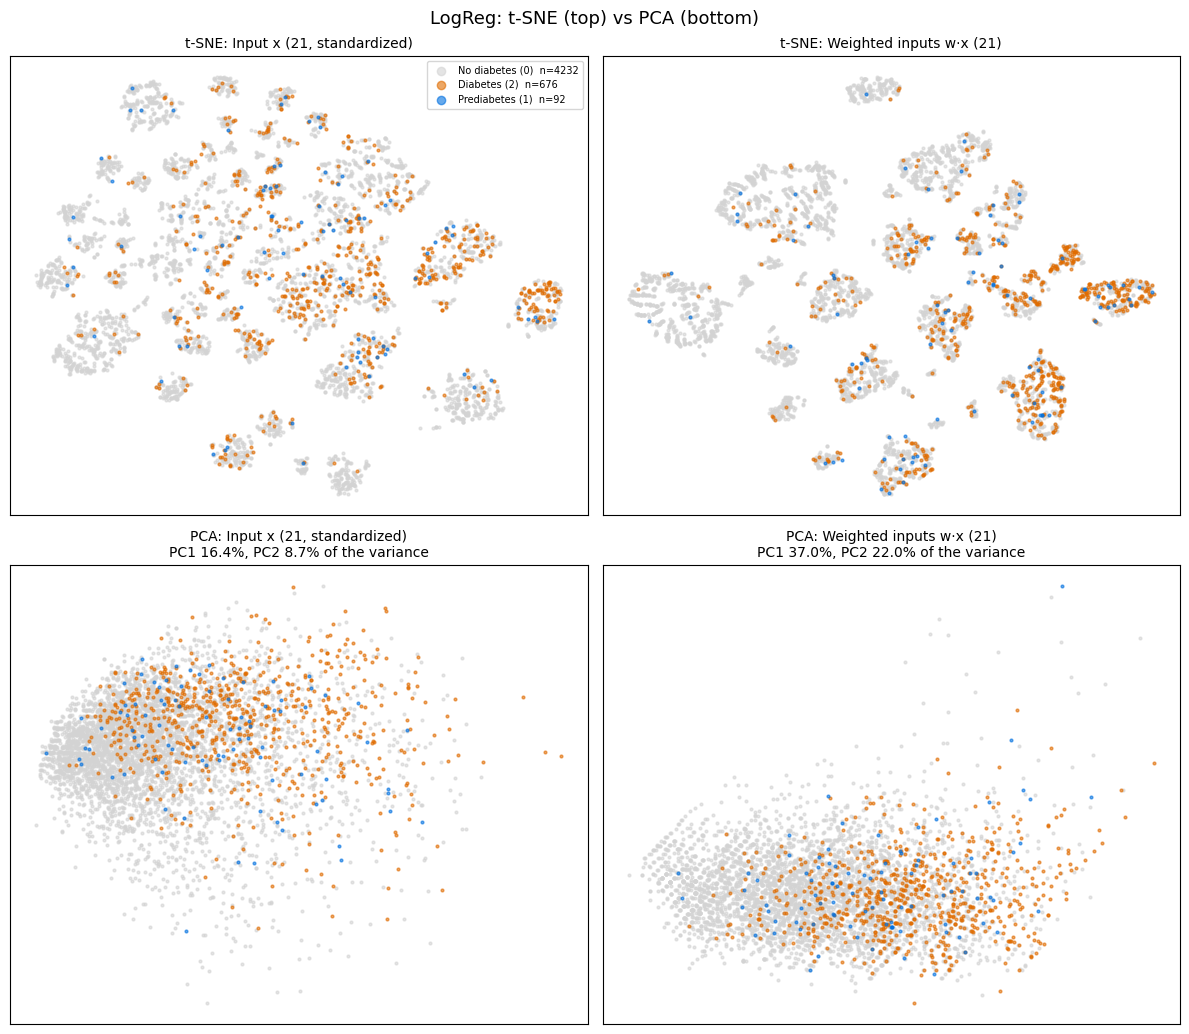

In [11]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], tsne_embs[name], title=f't-SNE: {name}', legend=(i == 0))
    scatter_by_label(axes[1, i], pca_embs[name], legend=False,
                     title=f'PCA: {name}\nPC1 {100*pca_vars[name][0]:.1f}%, PC2 {100*pca_vars[name][1]:.1f}% of the variance')
fig.suptitle(f'{MODEL_TAG}: t-SNE (top) vs PCA (bottom)', fontsize=13)
plt.tight_layout()
plt.show()

In [12]:
# How much does each PCA axis of the weighted inputs correlate with the model's logit?
for k in range(2):
    r = np.corrcoef(pca_embs[MAIN_REP][:, k], logit_lat)[0, 1]
    print(f'Correlation between PC{k + 1} of the weighted inputs and the logit: {r:+.3f}')

Correlation between PC1 of the weighted inputs and the logit: +0.895
Correlation between PC2 of the weighted inputs and the logit: -0.132


## 5. Exercise 3: the perplexity hyperparameter
Perplexity is roughly the number of neighbours each point "cares about".
- **Low perplexity**: very local, which tends to break the data into many small (often fake) clusters.
- **High perplexity**: more global structure, but small groups can disappear.

Note: our data has many binary features, so the input space already contains many "islands" (persons with the same combination of yes/no answers). These islands are real, but they are about the *data*, not the model.

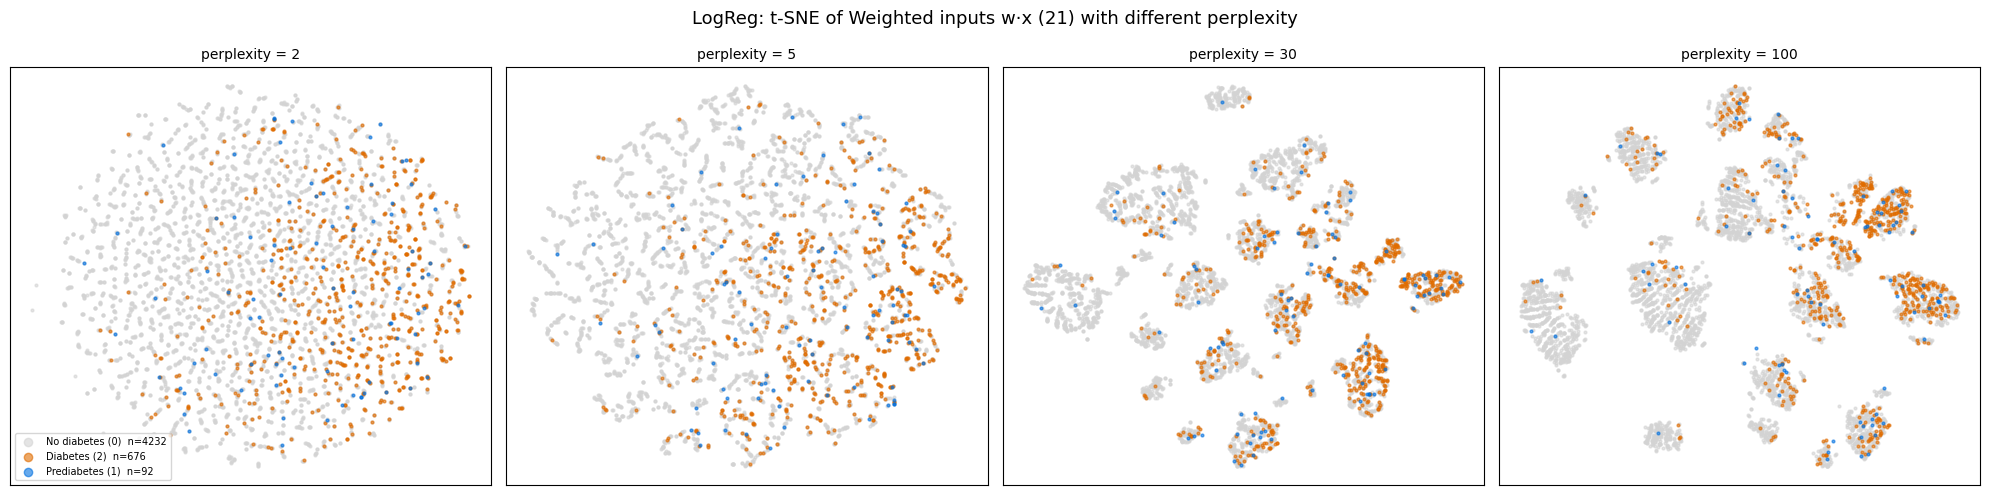

In [13]:
perplexities = [2, 5, 30, 100]
R = reps[MAIN_REP]

fig, axes = plt.subplots(1, len(perplexities), figsize=(5 * len(perplexities), 5))
for i, (ax, perp) in enumerate(zip(axes, perplexities)):
    emb = TSNE(**{**TSNE_KW, 'perplexity': perp}).fit_transform(R)
    scatter_by_label(ax, emb, title=f'perplexity = {perp}', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: t-SNE of {MAIN_REP} with different perplexity', fontsize=13)
plt.tight_layout()
plt.show()

### 5.1 Can t-SNE make clusters that are not real?
We run t-SNE on pure Gaussian noise with the same shape as our representation. Any cluster we see here is created by t-SNE itself.

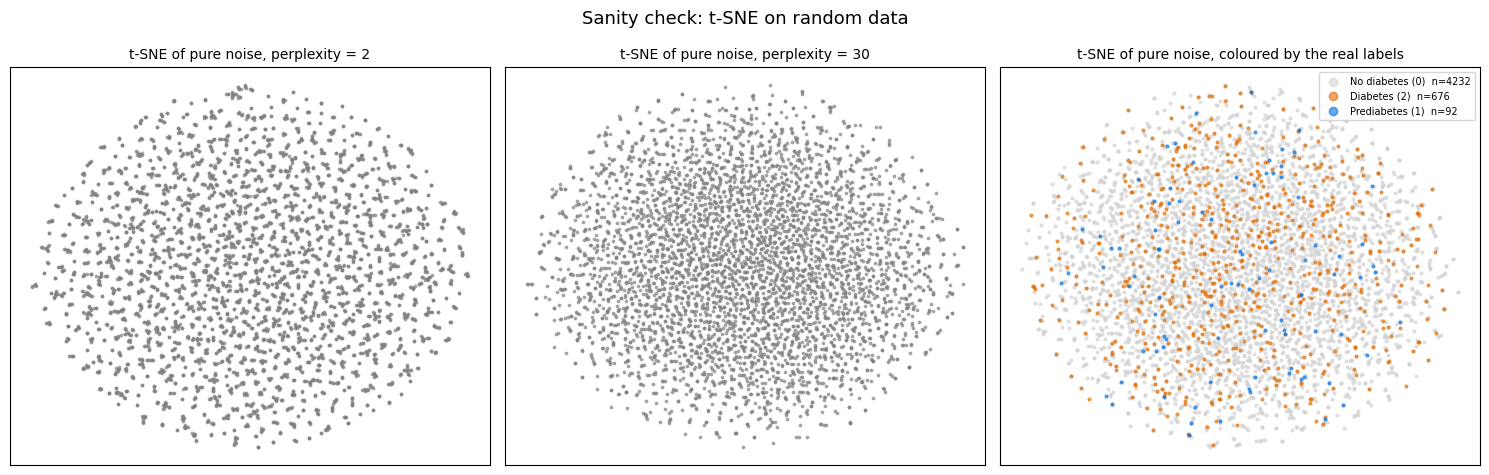

In [14]:
# Can t-SNE produce clusters that are not real?
# Gaussian noise with the same shape as our representation has NO cluster structure at all.
rng_noise = np.random.default_rng(SEED)
noise = rng_noise.standard_normal(reps[MAIN_REP].shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, perp in zip(axes, [2, 30]):
    emb = TSNE(**{**TSNE_KW, 'perplexity': perp, 'init': 'random'}).fit_transform(noise)
    ax.scatter(emb[:, 0], emb[:, 1], s=3, alpha=0.6, color='gray')
    ax.set_title(f't-SNE of pure noise, perplexity = {perp}', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

# Same noise, but with the real labels -> any "class separation" would be pure chance
emb = TSNE(**TSNE_KW).fit_transform(noise)
scatter_by_label(axes[2], emb, title='t-SNE of pure noise, coloured by the real labels', legend=True)
fig.suptitle('Sanity check: t-SNE on random data', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Exercise 4: UMAP
UMAP is like t-SNE built on a neighbour graph, but it usually keeps more of the global structure and is faster.

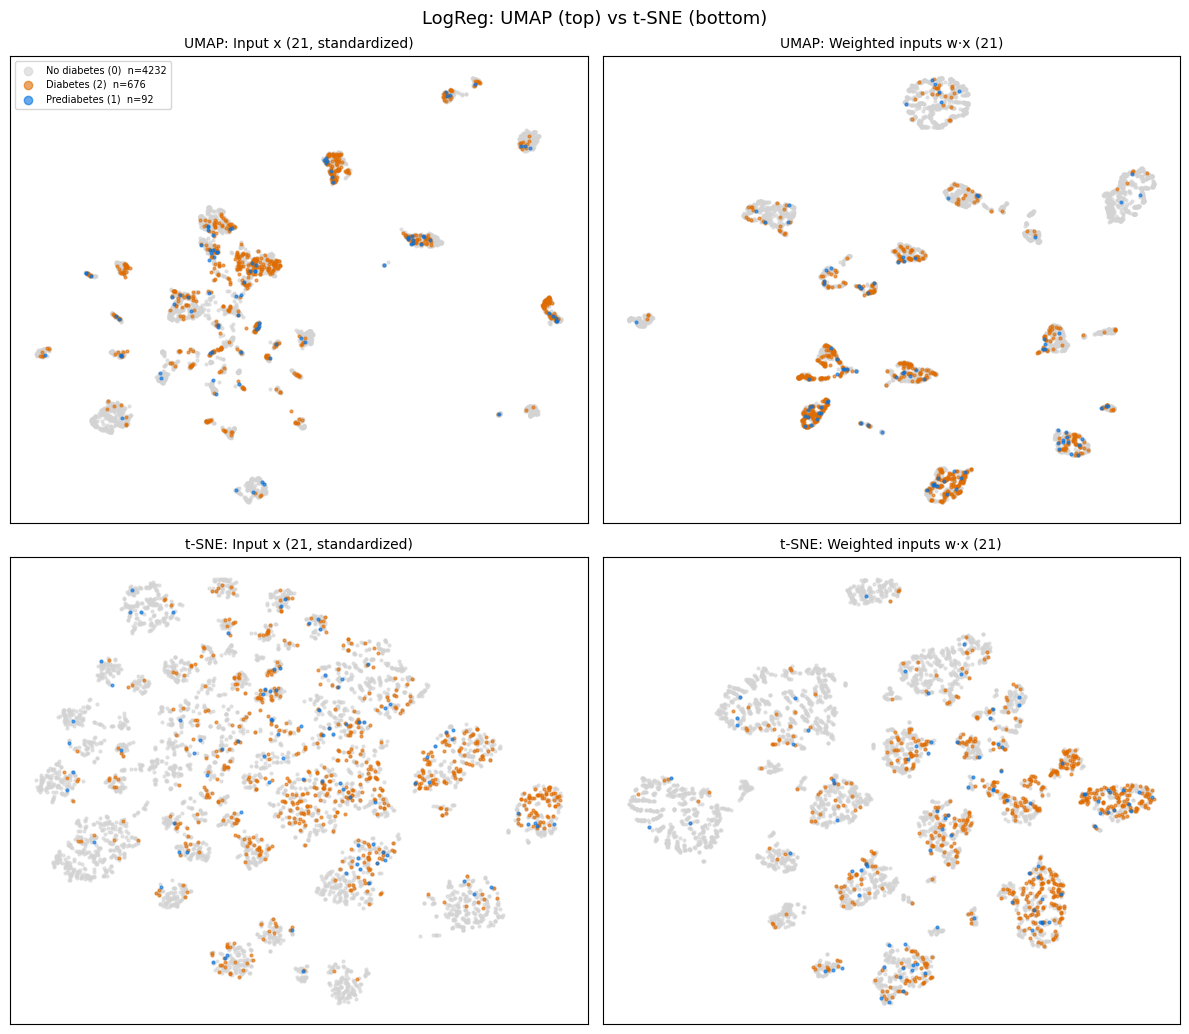

In [15]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], umap_embs[name], title=f'UMAP: {name}', legend=(i == 0))
    scatter_by_label(axes[1, i], tsne_embs[name], title=f't-SNE: {name}', legend=False)
fig.suptitle(f'{MODEL_TAG}: UMAP (top) vs t-SNE (bottom)', fontsize=13)
plt.tight_layout()
plt.show()

### 6.1 UMAP hyperparameters
- `n_neighbors`: like perplexity. Small = local structure, large = global structure.
- `min_dist`: how tightly points may be packed. Small = dense clumps, large = more evenly spread.

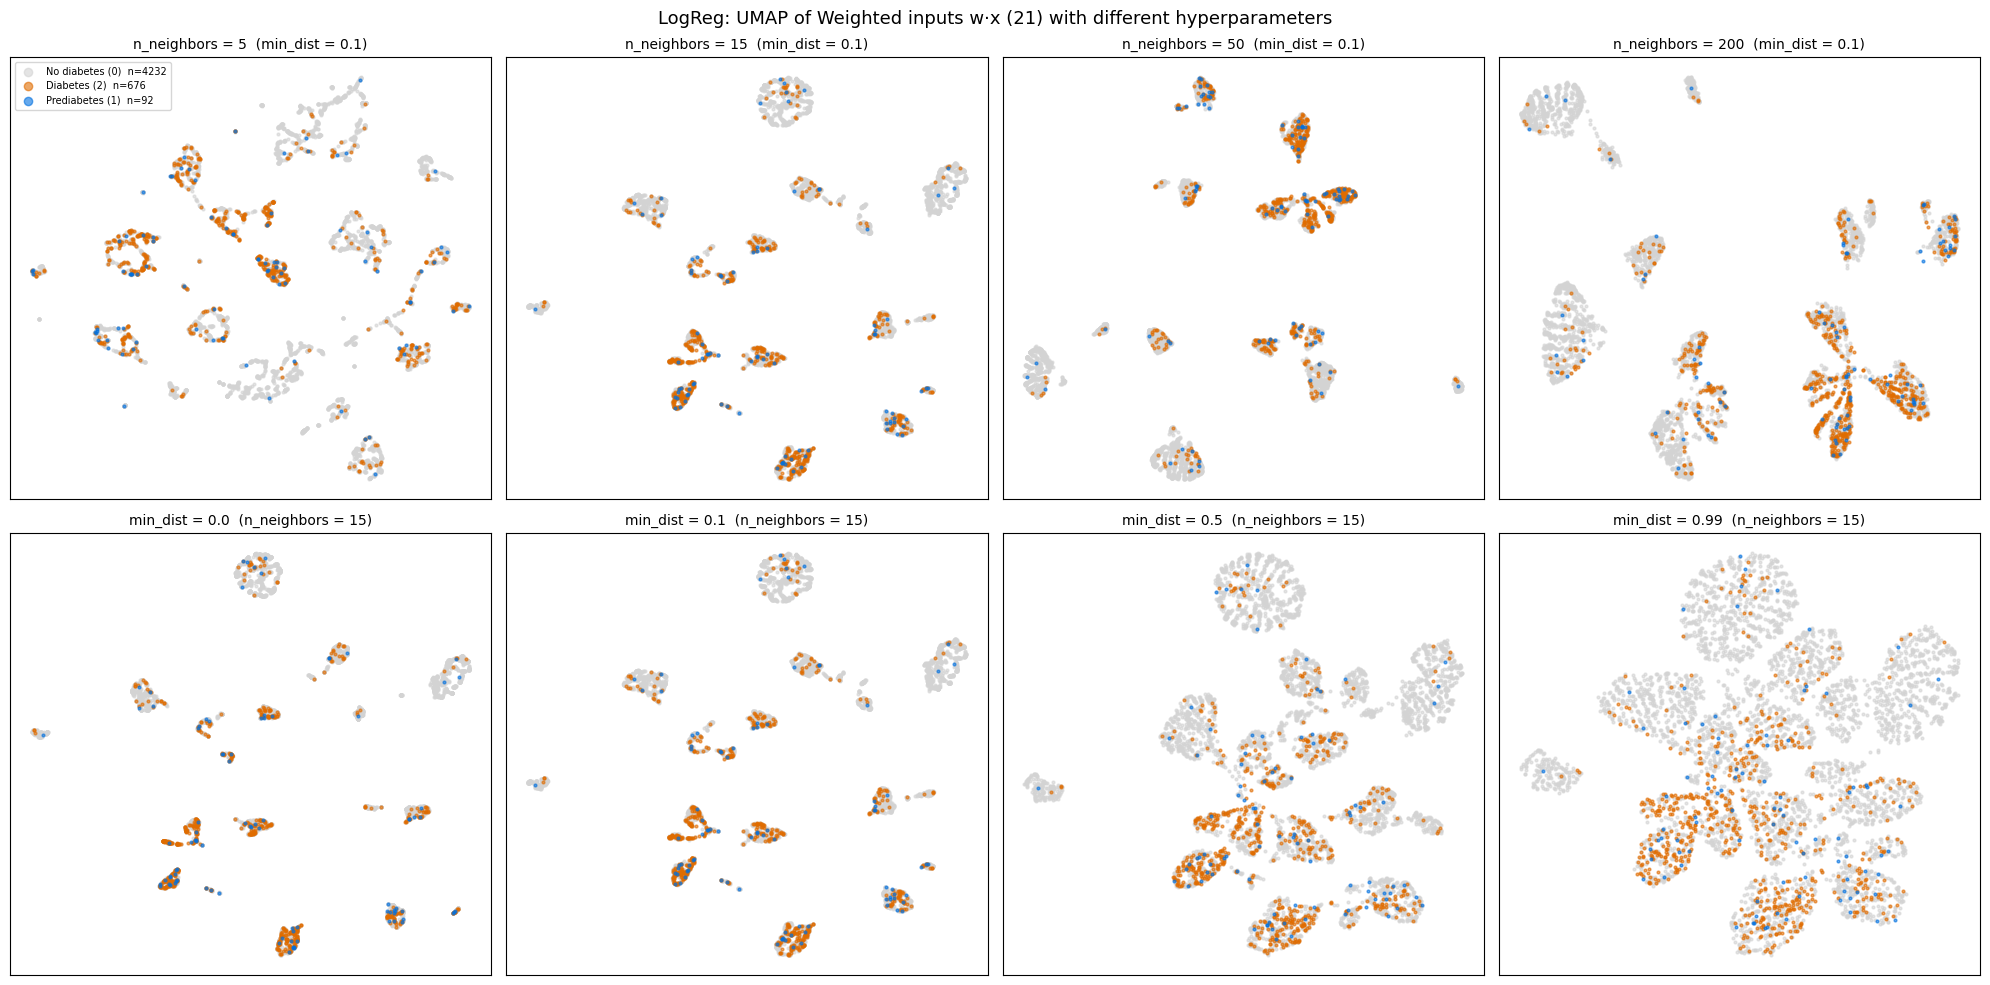

In [16]:
R = reps[MAIN_REP]
n_neighbors_list = [5, 15, 50, 200]
min_dist_list = [0.0, 0.1, 0.5, 0.99]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, nn_ in enumerate(n_neighbors_list):
    emb = umap.UMAP(**{**UMAP_KW, 'n_neighbors': nn_}).fit_transform(R)
    scatter_by_label(axes[0, i], emb, title=f'n_neighbors = {nn_}  (min_dist = 0.1)', legend=(i == 0))
for i, md_ in enumerate(min_dist_list):
    emb = umap.UMAP(**{**UMAP_KW, 'min_dist': md_}).fit_transform(R)
    scatter_by_label(axes[1, i], emb, title=f'min_dist = {md_}  (n_neighbors = 15)', legend=False)
fig.suptitle(f'{MODEL_TAG}: UMAP of {MAIN_REP} with different hyperparameters', fontsize=13)
plt.tight_layout()
plt.show()

## 7. What does the model encode?
### 7.1 Coloured by the model's prediction
For logistic regression the prediction is a smooth function of the weighted inputs, so we expect a smooth gradient from low to high risk.

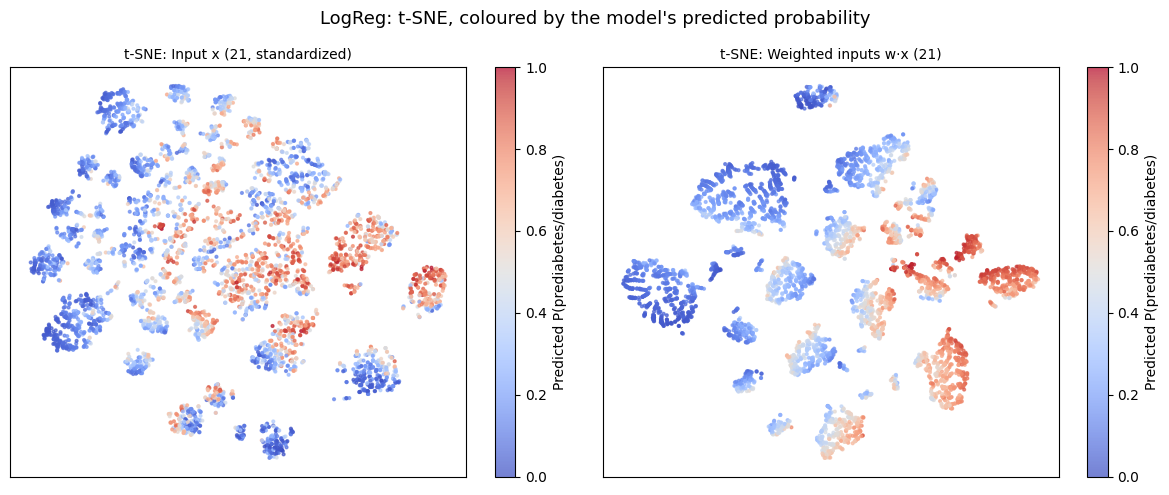

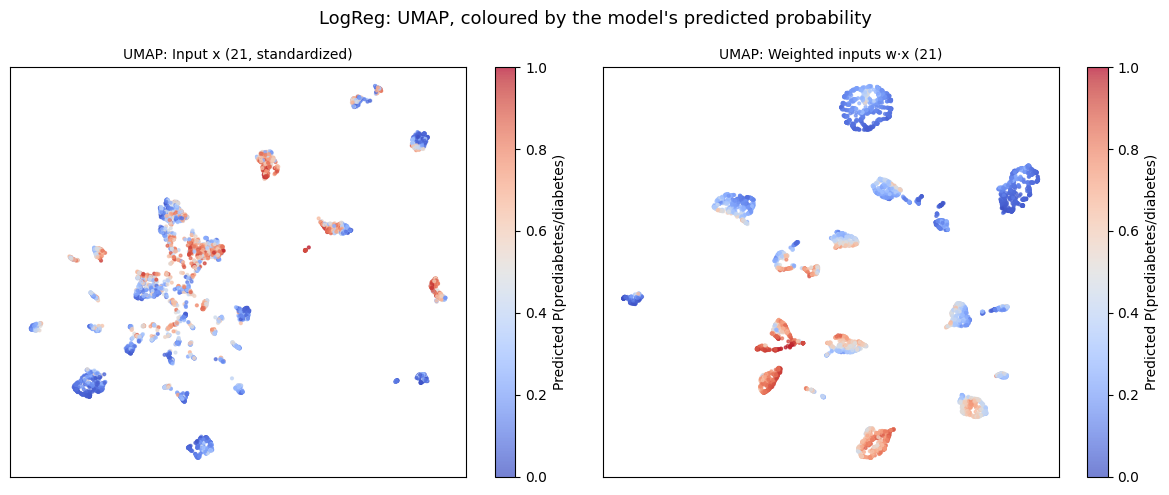

In [17]:
for method, embs in [('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
    fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5))
    for ax, name in zip(np.atleast_1d(axes), reps):
        scatter_by_value(ax, embs[name], lat_proba, title=f'{method}: {name}', cmap='coolwarm',
                         vmin=0, vmax=1, label='Predicted P(prediabetes/diabetes)')
    fig.suptitle(f'{MODEL_TAG}: {method}, coloured by the model\'s predicted probability', fontsize=13)
    plt.tight_layout()
    plt.show()

### 7.2 Coloured by input features (concepts)
In the weighted-input space, features with a large |weight| dominate the distances, so they should create the main gradients in the map. Compare with the weight plot in the main notebook.

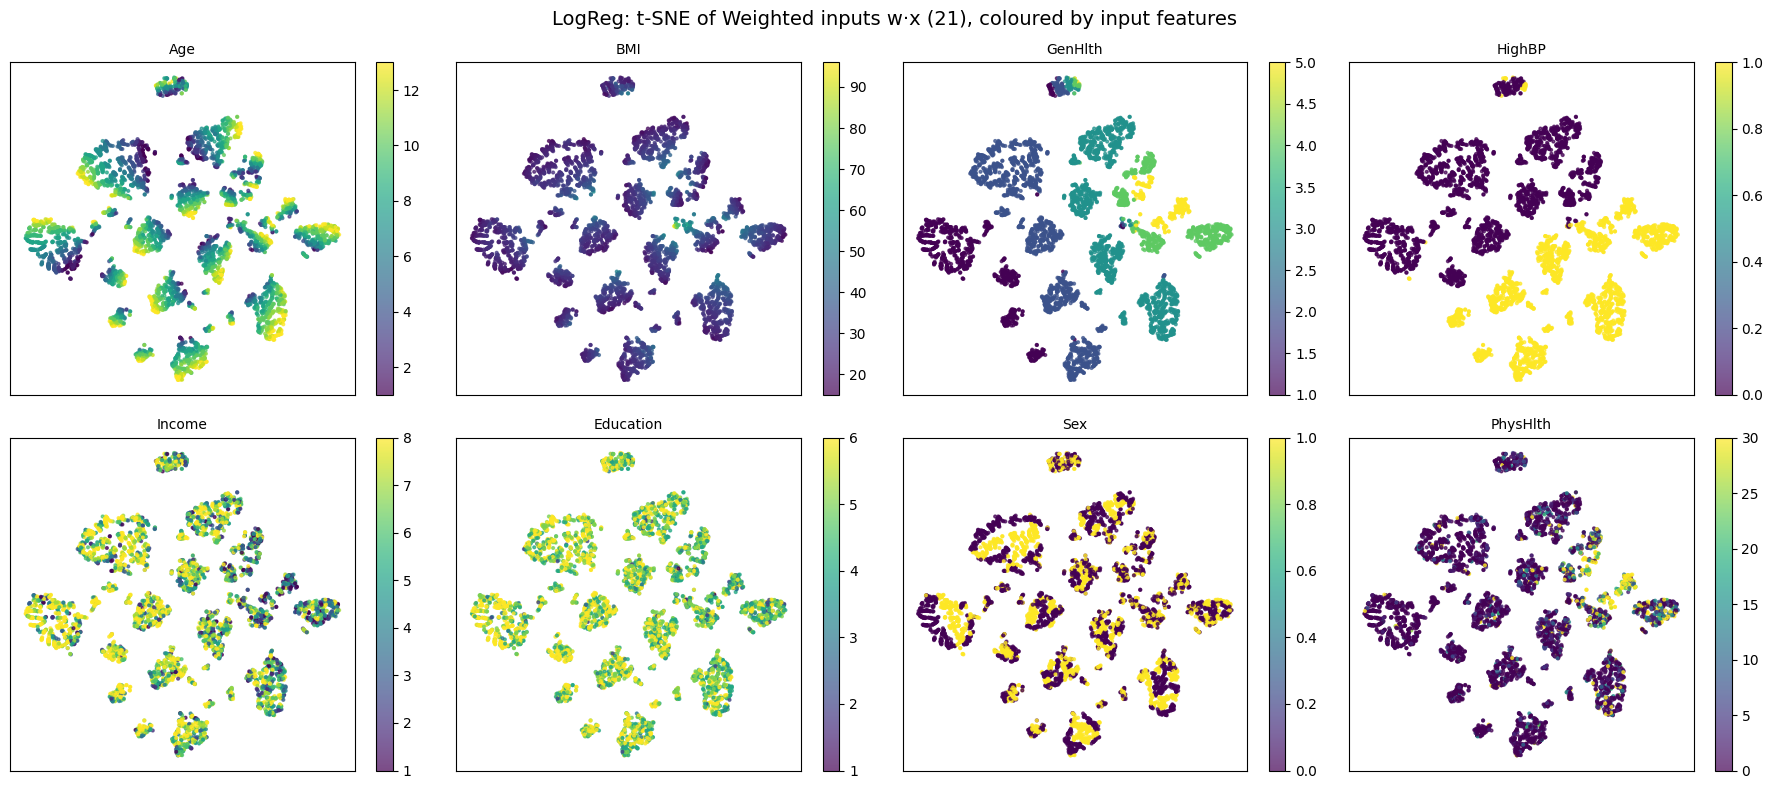

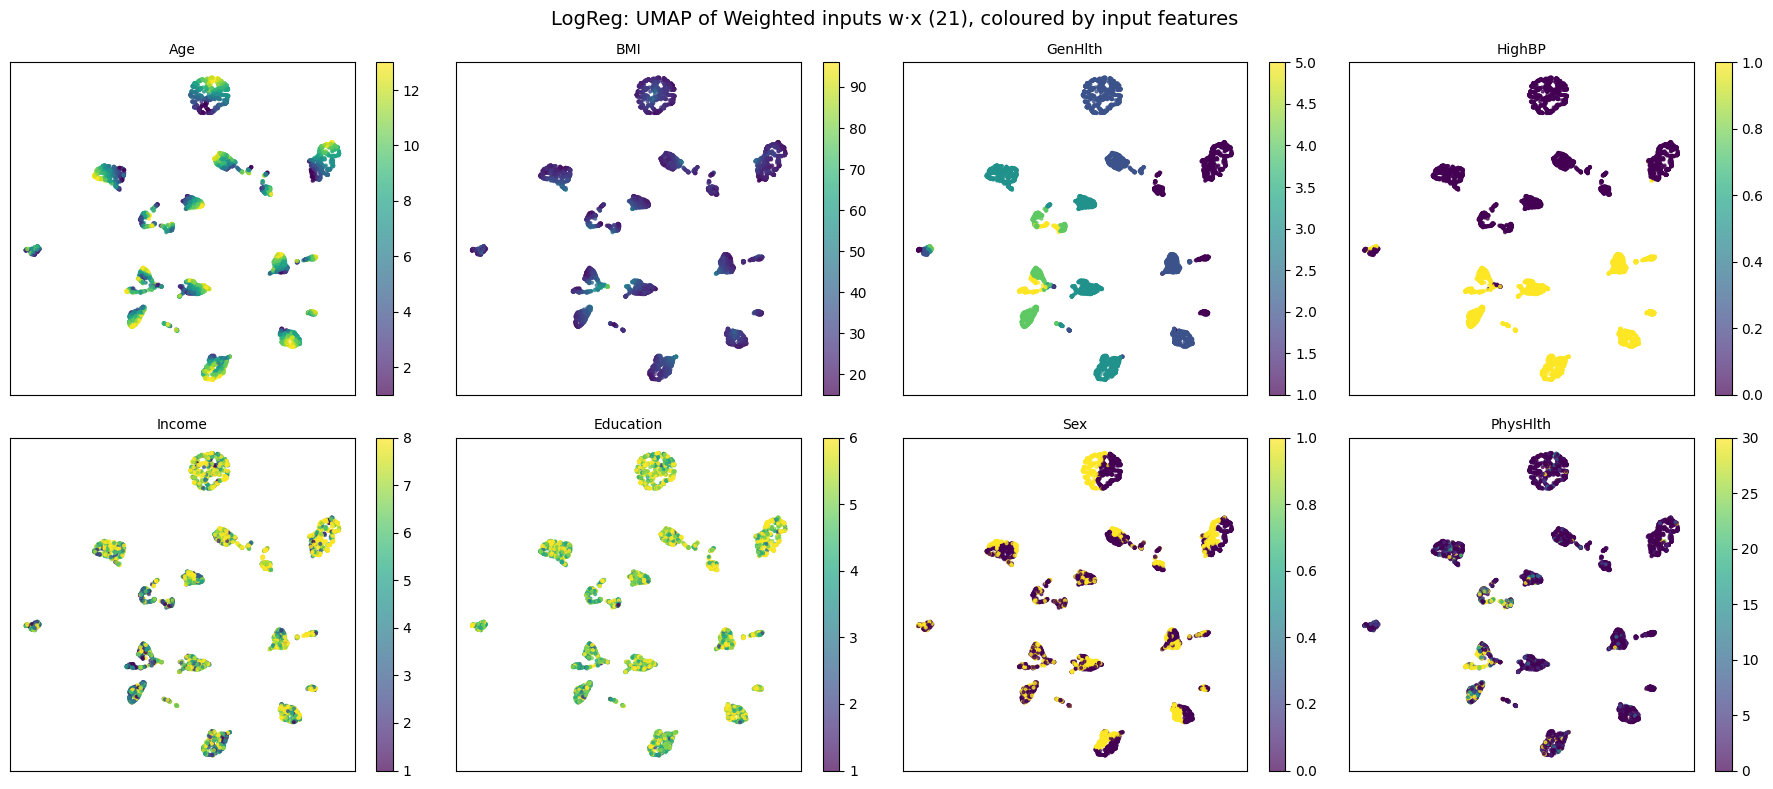

In [18]:
concept_features = ['Age', 'BMI', 'GenHlth', 'HighBP', 'Income', 'Education', 'Sex', 'PhysHlth']

for method, embs in [('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
    emb = embs[MAIN_REP]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.ravel(), concept_features):
        scatter_by_value(ax, emb, lat_raw[:, FEATURE_COLS.index(feat)], title=feat)
    fig.suptitle(f'{MODEL_TAG}: {method} of {MAIN_REP}, coloured by input features', fontsize=14)
    plt.tight_layout()
    plt.show()

## 8. How much do the 2-D maps preserve? (quantitative check)
The plots are easy to over-interpret, so we add two numbers per map:

- **Trustworthiness** (0–1): are the neighbours of a person in the 2-D map also neighbours in the original space? 1 = the map invents no false neighbours.
- **k-NN balanced accuracy** (binary label, k = 15, 5-fold CV): if we predict a person's label from their neighbours, how well does it work? This measures how well the label is *locally* separated. 0.5 = random.

The "original" rows are the reference: what the full representation contains before it is squeezed into 2-D.

In [19]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict


def knn_bal_acc(Z, labels, k=15):
    """Balanced accuracy of a k-NN classifier (5-fold CV): how well do neighbours share the label?"""
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    pred = cross_val_predict(knn, Z, labels, cv=5)
    return balanced_accuracy_score(labels, pred)


rows = []
for name, R in reps.items():
    rows.append({'representation': name, 'space': f'original ({R.shape[1]}-D)',
                 'trustworthiness (k=10)': 1.0, 'kNN balanced acc': knn_bal_acc(R, lat_y)})
    for method, embs in [('PCA', pca_embs), ('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
        Z = embs[name]
        rows.append({'representation': name, 'space': f'{method} (2-D)',
                     'trustworthiness (k=10)': trustworthiness(R, Z, n_neighbors=10),
                     'kNN balanced acc': knn_bal_acc(Z, lat_y)})

quant_df = pd.DataFrame(rows)
print(f'Model balanced accuracy on the same {N_LATENT} persons: '
      f'{balanced_accuracy_score(lat_y, (lat_proba >= 0.5).astype(int)):.3f}\n')
print(quant_df.round(3).to_string(index=False))

Model balanced accuracy on the same 5000 persons: 0.743

            representation           space  trustworthiness (k=10)  kNN balanced acc
Input x (21, standardized) original (21-D)                   1.000             0.545
Input x (21, standardized)       PCA (2-D)                   0.715             0.557
Input x (21, standardized)     t-SNE (2-D)                   0.992             0.556
Input x (21, standardized)      UMAP (2-D)                   0.977             0.543
  Weighted inputs w·x (21) original (21-D)                   1.000             0.588
  Weighted inputs w·x (21)       PCA (2-D)                   0.832             0.582
  Weighted inputs w·x (21)     t-SNE (2-D)                   0.999             0.592
  Weighted inputs w·x (21)      UMAP (2-D)                   0.996             0.565


## 9. What to look for
- Is the class separation clearer for the **weighted inputs** than for the raw input?
- Does **PC1** of the weighted inputs line up with the logit (Section 4)? Then a linear method is enough to see what this model does, and t-SNE/UMAP add little.
- Is the structure **stable** across perplexity / `n_neighbors`?
- Which **features** drive the gradients, and do they match the largest weights?
- Compare with `Project2_NN_latent_tSNE_UMAP.ipynb`: does the NN's hidden layer separate the classes better than the LR's weighted inputs? (k-NN column in Section 8)